# From One Decision Tree to a Random Forest: Predicting Diabetes

In this notebook we will teach a computer to answer a yes/no question: **does this patient have diabetes?**

We will do it in two stages:

1. First we build a single **decision tree**, a model that works like a flowchart of yes/no questions.
2. Then we build a **random forest**, which is simply *many* decision trees that vote together. We will build one **by hand, step by step**, so you can see exactly what happens inside, and then use the one-line scikit-learn version.

**Roadmap**

| Part | What we do |
|---|---|
| 0 | Look at the data |
| 1 | Build, draw, and evaluate a single decision tree |
| 2 | See the two big weaknesses of a single tree |
| 3 | Build a random forest by hand, one step at a time |
| 4 | Build a random forest with scikit-learn |
| 5 | Compare the models side by side |

> **How to use this notebook:** run the cells from top to bottom (Shift + Enter). Read the text above each code cell before you run it, and try to predict what will happen.

## Part 0: The Data

This dataset is originally from the National Institute of Diabetes and Digestive and Kidney Diseases. The objective of the dataset is to diagnostically predict whether or not a patient has diabetes, based on certain diagnostic measurements included in the dataset. Several constraints were placed on the selection of these instances from a larger database. In particular, all patients here are females at least 21 years old of Pima Indian heritage.

https://www.kaggle.com/uciml/pima-indians-diabetes-database/version/1#

**Each row is one patient.** Each column is one measurement about that patient:

| Column | What it means |
|---|---|
| `Pregnancies` | Number of times pregnant |
| `Glucose` | Blood sugar level 2 hours after drinking a sugary drink (glucose tolerance test) |
| `BloodPressure` | Diastolic blood pressure (mm Hg) |
| `SkinThickness` | Thickness of a skin fold on the back of the arm (mm), a rough measure of body fat |
| `Insulin` | Insulin level in the blood 2 hours after the sugary drink |
| `BMI` | Body mass index: weight (kg) / height (m)² |
| `DiabetesPedigreeFunction` | A score summarizing how much diabetes runs in the patient's family |
| `Age` | Age in years |
| `Outcome` | **What we want to predict:** 1 = has diabetes, 0 = does not |

Two words you will see a lot:

* **Features** are the inputs we use to make a prediction (the first 8 columns).
* The **target** (or *label*) is the answer we are trying to predict (`Outcome`).

In [47]:
# read the data into a Pandas DataFrame
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('pima_indians_diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [48]:
# how big is the dataset?
print("Number of patients (rows):", df.shape[0])
print("Number of columns:        ", df.shape[1])

Number of patients (rows): 768
Number of columns:         9


### Summary statistics

`describe()` gives a quick summary of every column: the average (`mean`), the smallest value (`min`), the largest value (`max`), and so on.

In [49]:
df.describe().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


**Look closely at the `min` row.** Some columns have a minimum of **0**: `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI`. A living person cannot have a blood pressure or BMI of 0! In this dataset, a 0 in these columns really means *"this measurement is missing."*

Real-world data is often messy like this. To keep our focus on the models, we will leave the zeros as they are for now (decision trees cope with this reasonably well). 

In [50]:
# how many 'impossible' zeros are in each column?
cols_with_fake_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
(df[cols_with_fake_zeros] == 0).sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

### How many patients have diabetes?

Before building any model, it is important to know how common each answer is. This gives us a **baseline**: the accuracy we would get by doing something really simple, like always guessing the most common answer. A useful model has to beat this baseline.

Outcome
0    500
1    268
Name: count, dtype: int64

If we ALWAYS guessed 'no diabetes', we would be right 65.1% of the time.


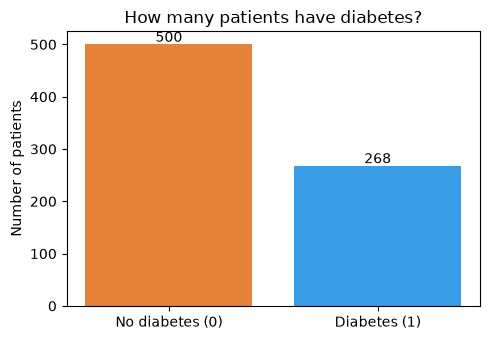

In [51]:
counts = df['Outcome'].value_counts().sort_index()
print(counts)
baseline = counts[0] / len(df)
print(f"\nIf we ALWAYS guessed 'no diabetes', we would be right {baseline:.1%} of the time.")

# colors used for the two classes throughout this notebook
# (these match the colors scikit-learn uses when it draws a tree: orange = class 0, blue = class 1)
NO_COLOR, YES_COLOR = '#e58139', '#399de5'

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(['No diabetes (0)', 'Diabetes (1)'], counts.values, color=[NO_COLOR, YES_COLOR])
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha='center')
ax.set_ylabel('Number of patients')
ax.set_title('How many patients have diabetes?')
plt.tight_layout()
plt.show()

### Which features look useful?

The histograms below show each feature twice: once for patients **without** diabetes (orange) and once for patients **with** diabetes (blue).

**What to look for:** if the orange and blue shapes sit in *different places*, that feature helps tell the two groups apart. If they overlap almost completely, that feature is not very helpful on its own. Which feature looks the most useful to you?

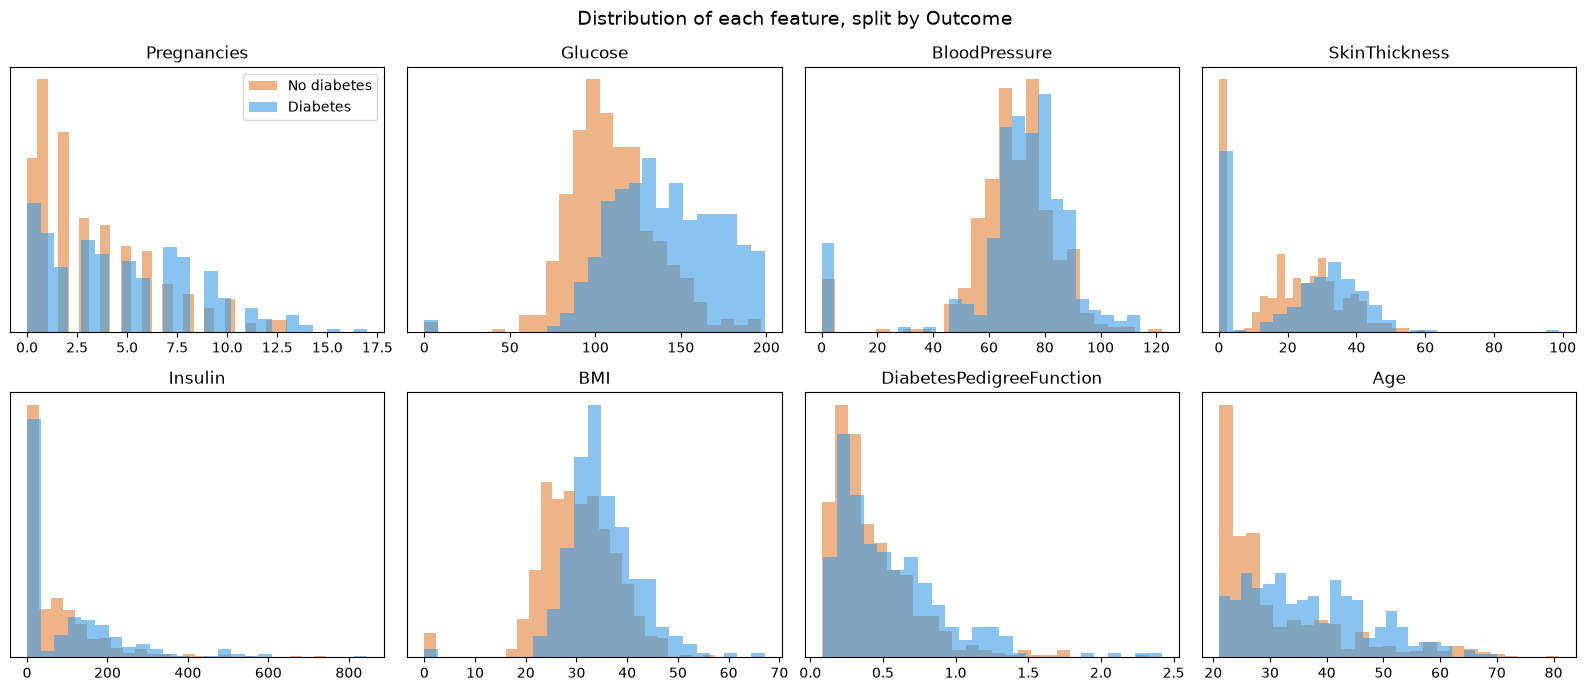

In [52]:
features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
            'BMI', 'DiabetesPedigreeFunction', 'Age']

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    ax.hist(df.loc[df['Outcome'] == 0, col], bins=25, alpha=0.6, density=True,
            color=NO_COLOR, label='No diabetes')
    ax.hist(df.loc[df['Outcome'] == 1, col], bins=25, alpha=0.6, density=True,
            color=YES_COLOR, label='Diabetes')
    ax.set_title(col)
    ax.set_yticks([])
axes[0, 0].legend()
fig.suptitle('Distribution of each feature, split by Outcome', fontsize=14)
plt.tight_layout()
plt.show()

### Define X and y

By convention in machine learning:

* `X` (capital) is the table of **features**, one row per patient.
* `y` (lowercase) is the column of **answers** (the target).

The model's job is to learn a rule that turns a row of `X` into the matching value of `y`.

In [53]:
# define X and y
X = df[['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age']]

y = df['Outcome']

### Split into a training set and a testing set

Imagine studying for an exam. If the exam used *exactly* the practice problems you studied, a perfect score would not prove you understood anything; you might have just memorized the answers.

We avoid this problem by hiding some of the data:

* **Training set (80%)**: the model is allowed to learn from these patients.
* **Testing set (20%)**: kept hidden until the very end. We use it to check how well the model does on patients it has **never seen**.

`random_state=1` makes the random split the same every time we run the notebook, so everyone gets the same results.

In [54]:
# split X and y into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=1)

print("Training patients:", len(X_train))
print("Testing patients: ", len(X_test))

Training patients: 614
Testing patients:  154


---
## Part 1: A Single Decision Tree

### What is a decision tree?

A decision tree is a **flowchart of yes/no questions**. It works a lot like the game *20 Questions*. To make a prediction for a patient, you start at the top, answer each question, follow the matching branch, and stop when you reach the end. A made-up example:

```
                 Is Glucose ≤ 130?
                 /               \
              yes                 no
              /                     \
      Is BMI ≤ 27?              Predict: DIABETES
       /        \
     yes         no
     /             \
Predict: NO     Predict: DIABETES
```

Some vocabulary:

* The **root node** is the first question at the top.
* A **branch** is one of the paths (yes or no) coming out of a question.
* A **leaf** is an end point. It contains a prediction instead of a question.

### How does the tree choose its questions?

The computer is not told what questions to ask; it figures them out from the training data. At each step it:

1. Tries **every feature** and **every possible cut-off value** (for example `Glucose ≤ 100`, `Glucose ≤ 101`, ..., `BMI ≤ 25`, ...).
2. For each one, splits the patients into a "yes" group and a "no" group.
3. Keeps the question that makes the two groups as **pure** as possible, meaning each group is mostly one kind of patient.

Then it repeats this inside each group, building the tree one question at a time.

### Measuring purity: Gini impurity

To compare questions, the tree needs a number that measures how mixed-up a group is. scikit-learn uses the **Gini impurity**:

$$\text{Gini} = 1 - p_{\text{no}}^2 - p_{\text{yes}}^2$$

where $p_{\text{no}}$ is the fraction of patients in the group without diabetes and $p_{\text{yes}}$ is the fraction with diabetes.

* A group that is **all one class** has Gini = **0** (perfectly pure).
* A group that is **half and half** has Gini = **0.5** (as mixed-up as possible with two classes).

Lower is better. Let's try a few examples.

In [55]:
def gini(n_no, n_yes):
    # Gini impurity of a group with n_no 'no' patients and n_yes 'yes' patients
    total = n_no + n_yes
    p_no = n_no / total
    p_yes = n_yes / total
    return 1 - p_no**2 - p_yes**2

print("10 no,  0 yes  -> Gini =", round(gini(10, 0), 3), "  (perfectly pure)")
print(" 8 no,  2 yes  -> Gini =", round(gini(8, 2), 3))
print(" 5 no,  5 yes  -> Gini =", round(gini(5, 5), 3), "  (as mixed as possible)")

10 no,  0 yes  -> Gini = 0.0   (perfectly pure)
 8 no,  2 yes  -> Gini = 0.32
 5 no,  5 yes  -> Gini = 0.5   (as mixed as possible)


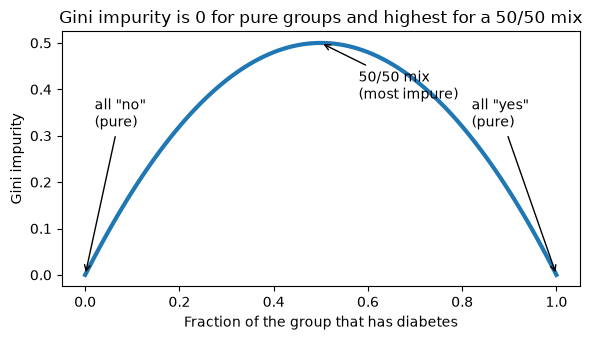

In [56]:
# picture of Gini impurity for every possible mix of the two classes
p_yes = np.linspace(0, 1, 101)
gini_values = 1 - (1 - p_yes)**2 - p_yes**2

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(p_yes, gini_values, linewidth=3)
ax.set_xlabel('Fraction of the group that has diabetes')
ax.set_ylabel('Gini impurity')
ax.set_title('Gini impurity is 0 for pure groups and highest for a 50/50 mix')
ax.annotate('all "no"\n(pure)', xy=(0, 0), xytext=(0.02, 0.32), arrowprops=dict(arrowstyle='->'))
ax.annotate('all "yes"\n(pure)', xy=(1, 0), xytext=(0.82, 0.32), arrowprops=dict(arrowstyle='->'))
ax.annotate('50/50 mix\n(most impure)', xy=(0.5, 0.5), xytext=(0.58, 0.38), arrowprops=dict(arrowstyle='->'))
plt.tight_layout()
plt.show()

### Train the tree

`max_leaf_nodes=3` limits the tree to **3 leaves**, which means it can only ask **2 questions**. A tiny tree like this is easy to draw and understand. (Later we will see what happens when we remove this limit.)

`fit` is the step where the model **learns** from the training data.

In [57]:
from sklearn.tree import DecisionTreeClassifier

# instantiate model
model = DecisionTreeClassifier(max_leaf_nodes=3, random_state=0)

# fit model
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",3
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at t

### Draw the tree

Each box in the picture shows:

* **The question** (first line), for example `Glucose <= 127.5`. If the answer is *yes*, go **left**; if *no*, go **right**. (Leaves have no question.)
* **gini**: how mixed-up the patients in this box are (0 = pure).
* **samples**: how many training patients reached this box.
* **value**: `[number without diabetes, number with diabetes]` in this box.
* **class**: the prediction for patients who end here (the majority in the box).

The color shows the majority class (**orange = no diabetes, blue = diabetes**, the same colors as our histograms), and darker colors mean purer boxes.

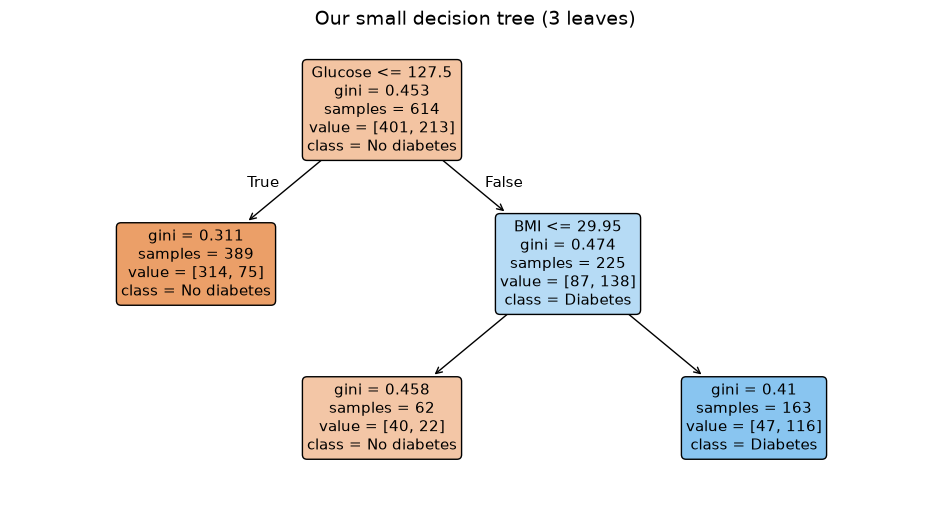

In [58]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(model, feature_names=X.columns, class_names=['No diabetes', 'Diabetes'],
          filled=True, rounded=True, fontsize=11, ax=ax)
ax.set_title('Our small decision tree (3 leaves)', fontsize=14)
plt.show()

The same tree can also be printed as plain-text rules:

In [59]:
from sklearn.tree import export_text
print(export_text(model, feature_names=list(X.columns)))

|--- Glucose <= 127.50
|   |--- class: 0
|--- Glucose >  127.50
|   |--- BMI <= 29.95
|   |   |--- class: 0
|   |--- BMI >  29.95
|   |   |--- class: 1



### Check the first question by hand

Let's prove the tree is not magic. We will take the root question that the tree picked and recompute its Gini numbers ourselves, using the `gini` function from earlier.

The **weighted Gini** after the split averages the two groups' Gini values, giving more weight to the bigger group. The tree picked the question that makes this number as **small** as possible.

In [60]:
# which feature and cut-off did the tree choose for its root question?
first_feature = X.columns[model.tree_.feature[0]]
threshold = model.tree_.threshold[0]
print(f"Root question: Is {first_feature} <= {threshold:.1f}?\n")

# split the training patients using that question
yes_group = y_train[X_train[first_feature] <= threshold]
no_group = y_train[X_train[first_feature] > threshold]

g_before = gini((y_train == 0).sum(), (y_train == 1).sum())
g_yes = gini((yes_group == 0).sum(), (yes_group == 1).sum())
g_no = gini((no_group == 0).sum(), (no_group == 1).sum())
g_after = (len(yes_group) * g_yes + len(no_group) * g_no) / len(y_train)

print(f"Before the split: {len(y_train)} patients, Gini = {g_before:.3f}")
print(f"'Yes' branch:     {len(yes_group)} patients, Gini = {g_yes:.3f}")
print(f"'No' branch:      {len(no_group)} patients, Gini = {g_no:.3f}")
print(f"Weighted Gini after the split = {g_after:.3f}  (lower than before, so the groups are purer)")

Root question: Is Glucose <= 127.5?

Before the split: 614 patients, Gini = 0.453
'Yes' branch:     389 patients, Gini = 0.311
'No' branch:      225 patients, Gini = 0.474
Weighted Gini after the split = 0.371  (lower than before, so the groups are purer)


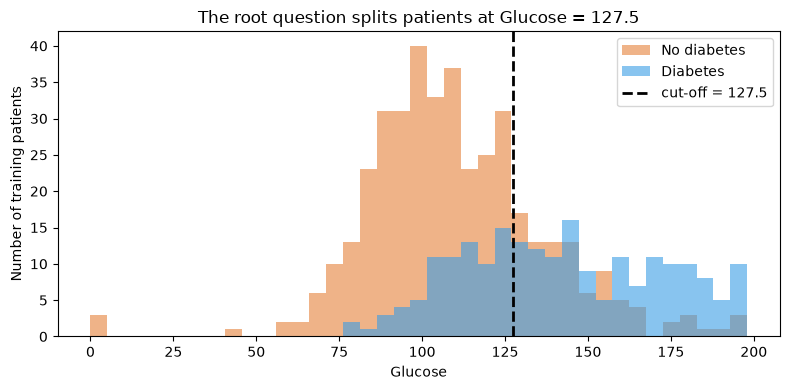

In [61]:
# picture of the root question: where does the cut-off fall?
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(X_train[first_feature].min(), X_train[first_feature].max(), 40)
ax.hist(X_train.loc[y_train == 0, first_feature], bins=bins, alpha=0.6, color=NO_COLOR, label='No diabetes')
ax.hist(X_train.loc[y_train == 1, first_feature], bins=bins, alpha=0.6, color=YES_COLOR, label='Diabetes')
ax.axvline(threshold, color='black', linestyle='--', linewidth=2, label=f'cut-off = {threshold:.1f}')
ax.set_xlabel(first_feature)
ax.set_ylabel('Number of training patients')
ax.set_title(f'The root question splits patients at {first_feature} = {threshold:.1f}')
ax.legend()
plt.tight_layout()
plt.show()

Most of the patients to the **left** of the dashed line do not have diabetes, while the patients to the **right** are much more likely to have it. That is why this question was chosen first: it separates the two groups better than any other single question.

### Make predictions on the test set

Now we use the tree on the **test patients** it has never seen. Each patient "falls down" the tree, answering the questions, until reaching a leaf. The prediction is that leaf's `class`.

In [62]:
# make class predictions for the testing set
y_pred_class = model.predict(X_test)
y_pred_class

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0])

### Compare predictions with the real answers

Let's put each test patient's actual outcome next to the model's prediction.

Note that we build this table from `X_test` (not the full `X`), because predictions only exist for the test patients. This keeps every prediction lined up with the right patient.

In [63]:
pred_df = X_test.copy()
pred_df['Actual'] = y_test
pred_df['Predicted'] = y_pred_class
pred_df['Correct?'] = pred_df['Actual'] == pred_df['Predicted']
pred_df.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Actual,Predicted,Correct?
285,7,136,74,26,135,26.0,0.647,51,0,0,True
101,1,151,60,0,0,26.1,0.179,22,0,0,True
581,6,109,60,27,0,25.0,0.206,27,0,0,True
352,3,61,82,28,0,34.4,0.243,46,0,0,True
726,1,116,78,29,180,36.1,0.496,25,0,0,True
472,0,119,66,27,0,38.8,0.259,22,0,0,True
233,4,122,68,0,0,35.0,0.394,29,0,0,True
385,1,119,54,13,50,22.3,0.205,24,0,0,True
556,1,97,70,40,0,38.1,0.218,30,0,0,True
59,0,105,64,41,142,41.5,0.173,22,0,0,True


### How good is the tree?

**Classification accuracy**: percentage of correct predictions

$$\text{Accuracy} = \frac{\text{number of correct predictions}}{\text{total number of predictions}}$$

In [64]:
# calculate accuracy
from sklearn import metrics
tree_acc = metrics.accuracy_score(y_test, y_pred_class)
print(f"Decision tree accuracy: {tree_acc:.3f}")
print(f"Baseline ('always guess no') accuracy on the test set: {(y_test == 0).mean():.3f}")

Decision tree accuracy: 0.799
Baseline ('always guess no') accuracy on the test set: 0.643


### The confusion matrix: *which* mistakes does the model make?

Accuracy is a single number, so it hides an important detail: **what kind of mistakes** the model makes. A **confusion matrix** counts all four possible outcomes:

| | Predicted: no diabetes | Predicted: diabetes |
|---|---|---|
| **Actually no diabetes** | True Negative (correct) | False Positive (false alarm) |
| **Actually diabetes** | False Negative (**missed case**) | True Positive (correct) |

In medicine, a **false negative** is often the most serious mistake: a sick patient is told they are healthy.

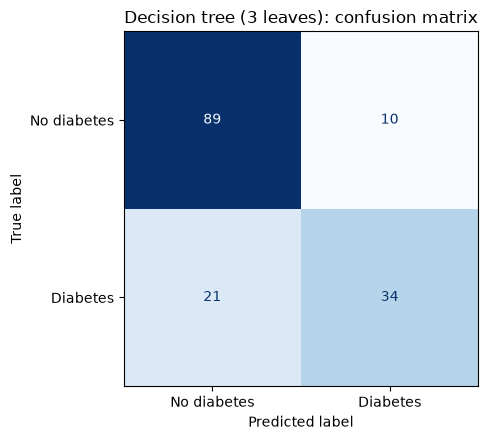

In [65]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_class,
                                        display_labels=['No diabetes', 'Diabetes'],
                                        cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Decision tree (3 leaves): confusion matrix')
plt.tight_layout()
plt.show()

### ROC AUC: how well does the model *rank* patients?

Besides a yes/no answer, a tree can give a **probability**: the fraction of diabetic training patients in the leaf where a test patient lands. **AUC** (area under the ROC curve) measures how well these probabilities rank patients:

* AUC = **0.5** means the model is no better than flipping a coin.
* AUC = **1.0** means every diabetic patient gets a higher risk score than every non-diabetic patient.

A simple way to read it: *AUC is the chance that a randomly chosen diabetic patient receives a higher risk score than a randomly chosen non-diabetic patient.*

AUC should be computed from the **probabilities** (`predict_proba`), not from the 0/1 predictions. We show both below; the version based on probabilities is the correct one to report.

In [66]:
# probability of diabetes (class 1) for each test patient
y_pred_prob = model.predict_proba(X_test)[:, 1]

print("AUC using 0/1 predictions (not recommended):", round(metrics.roc_auc_score(y_test, y_pred_class), 3))
print("AUC using probabilities (correct):           ", round(metrics.roc_auc_score(y_test, y_pred_prob), 3))
print("\nDistinct probability values this tree can output:", np.unique(y_pred_prob).round(3))

AUC using 0/1 predictions (not recommended): 0.759
AUC using probabilities (correct):            0.752

Distinct probability values this tree can output: [0.193 0.355 0.712]


Because our tree has only 3 leaves, it can only give **3 different risk scores**. That is a very coarse way to rank patients. Keep this in mind; the random forest will do much better here.



## Part 2: Why One Tree Is Not Enough

A single decision tree is easy to understand, but it has two big weaknesses.

### Weakness 1: Big trees memorize (overfitting)

Our tree had only 3 leaves. What if we let it grow bigger? A bigger tree can ask more questions, so it should fit the training data better. But does it do better on **new** patients?

Below we grow trees of increasing **depth** (the number of questions in a row from the root to the deepest leaf) and measure accuracy on both the training set and the test set.

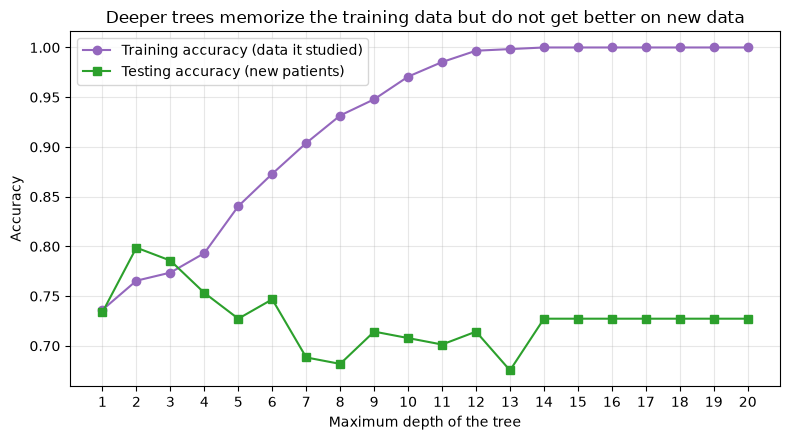

In [67]:
depths = range(1, 21)
train_scores, test_scores = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    train_scores.append(t.score(X_train, y_train))   # .score() returns accuracy
    test_scores.append(t.score(X_test, y_test))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(depths, train_scores, 'o-', color='tab:purple', label='Training accuracy (data it studied)')
ax.plot(depths, test_scores, 's-', color='tab:green', label='Testing accuracy (new patients)')
ax.set_xlabel('Maximum depth of the tree')
ax.set_ylabel('Accuracy')
ax.set_title('Deeper trees memorize the training data but do not get better on new data')
ax.set_xticks(list(depths))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

As the tree gets deeper, **training accuracy climbs toward 100%**: the tree ends up with tiny leaves that each describe just a handful of patients. But **testing accuracy does not keep up**. The tree has started memorizing details and noise that are specific to the training patients and do not carry over to new ones.

This is called **overfitting**. It is exactly the "memorized the practice exam" problem from earlier.

Let's look at a fully grown tree with no limits at all:

In [68]:
full_tree = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)

print("Number of leaves:  ", full_tree.get_n_leaves())
print("Depth:             ", full_tree.get_depth())
print(f"Training accuracy:  {full_tree.score(X_train, y_train):.3f}")
print(f"Testing accuracy:   {full_tree.score(X_test, y_test):.3f}")

Number of leaves:   110
Depth:              14
Training accuracy:  1.000
Testing accuracy:   0.727


### Weakness 2: Small changes in the data give a very different tree (instability)

A good model should not change much if we remove a few patients from the training data. Let's test that. We will build 5 fully grown trees, each trained on a **random 90%** of the training patients, and see whether they agree.

In [69]:
rng = np.random.default_rng(7)
test_predictions = []

for i in range(5):
    keep = rng.choice(len(X_train), size=int(0.9 * len(X_train)), replace=False)
    t = DecisionTreeClassifier(random_state=0).fit(X_train.iloc[keep], y_train.iloc[keep])

    # describe the first two levels of questions
    f, thr = t.tree_.feature, t.tree_.threshold
    left, right = t.tree_.children_left[0], t.tree_.children_right[0]
    def q(node):
        return f"{X.columns[f[node]]} <= {thr[node]:.1f}" if f[node] >= 0 else "(leaf)"
    print(f"Tree {i+1}: root: {q(0):<26} | left: {q(left):<32} | right: {q(right):<32} "
          f"| test accuracy {t.score(X_test, y_test):.3f}")
    test_predictions.append(t.predict(X_test))

test_predictions = np.array(test_predictions)
disagree = (test_predictions.min(axis=0) != test_predictions.max(axis=0)).mean()
print(f"\nThe 5 trees DISAGREE on {disagree:.0%} of the test patients.")

Tree 1: root: Glucose <= 130.5           | left: BMI <= 26.3                      | right: BMI <= 29.8                      | test accuracy 0.669
Tree 2: root: Glucose <= 129.5           | left: BMI <= 26.2                      | right: BMI <= 29.9                      | test accuracy 0.656
Tree 3: root: Glucose <= 127.5           | left: Glucose <= 99.5                  | right: BMI <= 29.8                      | test accuracy 0.727
Tree 4: root: Glucose <= 127.5           | left: Age <= 28.5                      | right: Glucose <= 165.5                 | test accuracy 0.682
Tree 5: root: Glucose <= 130.5           | left: BMI <= 26.3                      | right: Glucose <= 154.5                 | test accuracy 0.695

The 5 trees DISAGREE on 61% of the test patients.


Removing just 10% of the patients changes the questions further down the tree, changes the accuracy, and changes the predictions for many patients. A model whose answers depend this much on *which* patients happened to be in the training set is called **unstable** (statisticians say it has **high variance**).

**So here is the challenge:** big trees are powerful but they memorize, and they change a lot with small changes in the data. Can we keep the power and remove the instability?

**Yes. The answer is the random forest.**

---
## Part 3: Building a Random Forest by Hand, Step by Step

### The big idea: the wisdom of crowds

Suppose 500 people each guess how many jelly beans are in a jar. Most individual guesses are quite wrong, some too high and some too low. But the **average** of all the guesses is often amazingly close to the true number, because the individual errors cancel each other out.

A random forest uses the same trick: build **many** decision trees and let them **vote**.

There is one catch. The crowd only works if the members make **different** mistakes. If all 500 people copied the same person's guess, averaging would not help at all. If we trained 100 trees on the exact same data, we would get 100 identical trees, and voting would be pointless.

So a random forest adds **two kinds of randomness** to make the trees different from each other:

```
                          Training data (614 patients)
                                     |
        +-------------------+--------+-----------+-------------------+
        |                   |                    |                   |
 STEP 1: Bootstrap   Bootstrap sample 2   Bootstrap sample 3  ...  sample N
     sample 1               |                    |                   |
        |                   |                    |                   |
 STEP 2 & 3: grow a tree, using only a random few features at each question
     Tree 1              Tree 2               Tree 3        ...    Tree N
        |                   |                    |                   |
       vote                vote                 vote                vote
        +-------------------+--------+-----------+-------------------+
                                     |
                STEP 4: Majority vote = final prediction
```

Let's go through each step.

### Step 1: Bootstrap sampling (random rows)

Each tree gets its own version of the training data, made by **sampling with replacement**:

* Imagine writing every patient's ID on a slip of paper and putting the slips in a hat.
* Draw one slip, write down the ID, and **put the slip back** in the hat.
* Repeat until you have drawn as many slips as there are patients.

Because slips go back into the hat, some patients get picked **two or three times**, and others are **never picked**. This new dataset is called a **bootstrap sample**. Every tree gets a different one.

Let's try it with a tiny "dataset" of 10 patients:

In [70]:
rng = np.random.default_rng(42)
patients = np.arange(10)       # patient IDs 0, 1, ..., 9

boot = rng.choice(patients, size=10, replace=True)   # replace=True means "put the slip back"
print("Original patients:", patients)
print("Bootstrap sample: ", np.sort(boot))
print("Never picked:     ", sorted(int(p) for p in set(patients) - set(boot)))

Original patients: [0 1 2 3 4 5 6 7 8 9]
Bootstrap sample:  [0 0 0 2 4 4 6 6 7 8]
Never picked:      [1, 3, 5, 9]


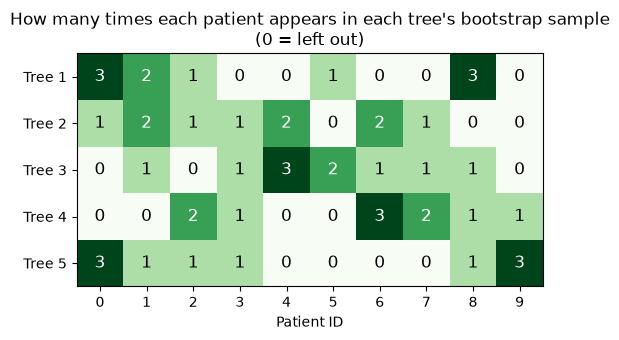

In [71]:
# draw 5 bootstrap samples and show how many times each patient was picked
rng = np.random.default_rng(3)
n_samples = 5
pick_counts = np.zeros((n_samples, 10), dtype=int)
for s in range(n_samples):
    boot = rng.choice(10, size=10, replace=True)
    for p in boot:
        pick_counts[s, p] += 1

fig, ax = plt.subplots(figsize=(9, 3.5))
im = ax.imshow(pick_counts, cmap='Greens', vmin=0, vmax=pick_counts.max())
for s in range(n_samples):
    for p in range(10):
        ax.text(p, s, pick_counts[s, p], ha='center', va='center',
                color='white' if pick_counts[s, p] >= 2 else 'black', fontsize=12)
ax.set_xticks(range(10))
ax.set_xlabel('Patient ID')
ax.set_yticks(range(n_samples))
ax.set_yticklabels([f'Tree {s+1}' for s in range(n_samples)])
ax.set_title('How many times each patient appears in each tree\'s bootstrap sample\n(0 = left out)')
plt.tight_layout()
plt.show()

Every row (every tree's dataset) is different. Patients with a **0** were left out of that tree's data, and patients with a **2** or **3** count extra.

How many patients does a bootstrap sample actually contain? Let's check on the real training set. (It is a famous result that, on average, about **63%** of the patients get picked at least once and about **37%** are left out.)

In [72]:
rng = np.random.default_rng(0)
n = len(X_train)
for i in range(5):
    boot_idx = rng.choice(n, size=n, replace=True)
    unique = len(np.unique(boot_idx))
    print(f"Bootstrap sample {i+1}: {n} draws, {unique} different patients "
          f"({unique/n:.1%}), {n - unique} patients left out")

Bootstrap sample 1: 614 draws, 380 different patients (61.9%), 234 patients left out
Bootstrap sample 2: 614 draws, 379 different patients (61.7%), 235 patients left out
Bootstrap sample 3: 614 draws, 389 different patients (63.4%), 225 patients left out
Bootstrap sample 4: 614 draws, 387 different patients (63.0%), 227 patients left out
Bootstrap sample 5: 614 draws, 385 different patients (62.7%), 229 patients left out


### Step 2: Random features at each question

Remember from Part 0 that `Glucose` is a very strong feature. If every tree were allowed to look at all 8 features, almost every tree would pick a `Glucose` question first, and the trees would end up looking very similar. Similar trees make similar mistakes, so voting would not help much.

The fix: **every time a tree asks a question, it may only consider a small random handful of the features.** A common choice is the square root of the number of features: $\sqrt{8} \approx 2.8$, so scikit-learn uses **2 features** per question. A new random handful is drawn for *every* question in *every* tree.

Sometimes `Glucose` is not in the handful, so the tree has to make do with something else, such as `BMI` or `Age`. This forces the trees to discover different patterns.

Here is what drawing 2 random features looks like for 6 different questions:

In [73]:
rng = np.random.default_rng(1)
n_features_per_question = int(np.sqrt(len(features)))   # sqrt(8) = 2.83 -> 2
print("Features allowed per question:", n_features_per_question, "\n")
for question in range(1, 7):
    allowed = rng.choice(features, size=n_features_per_question, replace=False)
    print(f"Question {question}: the tree may only choose between {' and '.join(allowed)}")

Features allowed per question: 2 

Question 1: the tree may only choose between SkinThickness and Insulin
Question 2: the tree may only choose between Pregnancies and DiabetesPedigreeFunction
Question 3: the tree may only choose between Age and BMI
Question 4: the tree may only choose between DiabetesPedigreeFunction and BloodPressure
Question 5: the tree may only choose between DiabetesPedigreeFunction and Glucose
Question 6: the tree may only choose between BloodPressure and BMI


In scikit-learn we don't have to write this ourselves: the option `max_features='sqrt'` in `DecisionTreeClassifier` does exactly this.

### Step 3: Grow many trees

Now we combine Steps 1 and 2. We make **25 trees**. Each one gets:

* its own bootstrap sample of the training patients (Step 1), and
* a random handful of features at every question (Step 2).

Notice that we let each tree **grow fully** with no size limit. In Part 2 we saw that a single big tree overfits. That is okay here: each tree overfits in its *own* way, and the vote in Step 4 will cancel much of that out.

In [74]:
n_trees = 25
my_trees = []
rng = np.random.default_rng(0)
n = len(X_train)

for i in range(n_trees):
    # Step 1: bootstrap sample of the training patients
    boot_idx = rng.choice(n, size=n, replace=True)
    X_boot = X_train.iloc[boot_idx]
    y_boot = y_train.iloc[boot_idx]

    # Step 2 + 3: grow a full tree that sees only sqrt(8) = 2 random features at each question
    tree = DecisionTreeClassifier(max_features='sqrt', random_state=i)
    tree.fit(X_boot, y_boot)
    my_trees.append(tree)

print(f"Built {len(my_trees)} trees.")

Built 25 trees.


Are the trees really different from each other? Let's count which feature each tree used for its **root question**:

Glucose                     5
Age                         5
BMI                         5
Pregnancies                 3
SkinThickness               2
Insulin                     2
DiabetesPedigreeFunction    2
BloodPressure               1
Name: count, dtype: int64


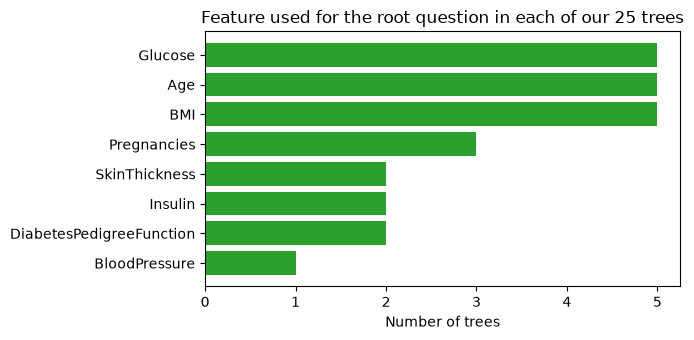

In [75]:
root_features = [X.columns[t.tree_.feature[0]] for t in my_trees]
root_counts = pd.Series(root_features).value_counts()
print(root_counts)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(root_counts.index[::-1], root_counts.values[::-1], color='tab:green')
ax.set_xlabel('Number of trees')
ax.set_title(f'Feature used for the root question in each of our {n_trees} trees')
plt.tight_layout()
plt.show()

Instead of 25 copies of the same `Glucose` question, the trees start with a variety of features. Let's draw the **top two levels** of three of the trees to see how different they are. (The trees are much bigger than this; we cut the drawing off at depth 2 so it stays readable. Boxes labeled `(...)` hide the rest of the tree.)

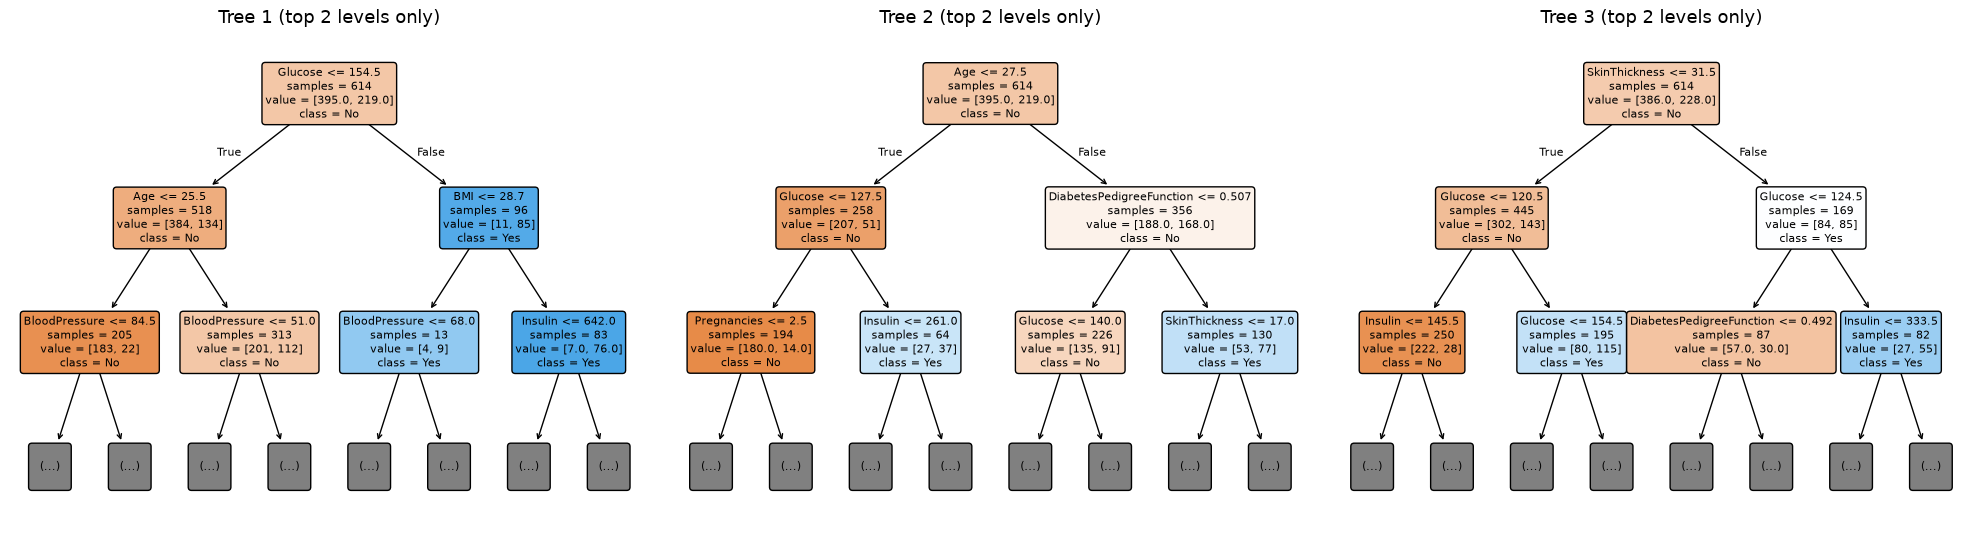

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, i in zip(axes, [0, 1, 2]):
    plot_tree(my_trees[i], max_depth=2, feature_names=X.columns,
              class_names=['No', 'Yes'], filled=True, rounded=True,
              impurity=False, fontsize=8, ax=ax)
    ax.set_title(f'Tree {i+1} (top 2 levels only)', fontsize=13)
plt.tight_layout()
plt.show()

### Step 4: Let the trees vote

To predict a test patient, we ask **every tree** for its prediction and take the **majority vote**. With 25 trees, if 13 or more trees say "diabetes", the forest says "diabetes".

Let's look at the votes for the first 8 test patients:

In [77]:
# every tree predicts every test patient
# all_votes has one row per tree and one column per test patient
all_votes = np.array([t.predict(X_test) for t in my_trees])
print("Shape of all_votes (trees, test patients):", all_votes.shape)

yes_votes = all_votes.sum(axis=0)              # how many trees said "diabetes"
my_forest_pred = (yes_votes > n_trees / 2).astype(int)   # majority vote

vote_table = pd.DataFrame({
    'Votes for "no"': n_trees - yes_votes,
    'Votes for "diabetes"': yes_votes,
    'Forest prediction': my_forest_pred,
    'Actual': y_test.values,
}, index=X_test.index)
vote_table.head(8)

Shape of all_votes (trees, test patients): (25, 154)


,"Votes for ""no""","Votes for ""diabetes""",Forest prediction,Actual
285,12,13,1,0
101,22,3,0,0
581,24,1,0,0
352,22,3,0,0
726,23,2,0,0
472,20,5,0,0
233,17,8,0,0
385,23,2,0,0


The picture below shows every vote for the first 25 test patients. Each **column** is a patient and each **row** is a tree. The two rows at the bottom show the forest's majority vote and the true answer.

Notice how individual trees often get a patient wrong, but the majority is right more often than most individual trees.

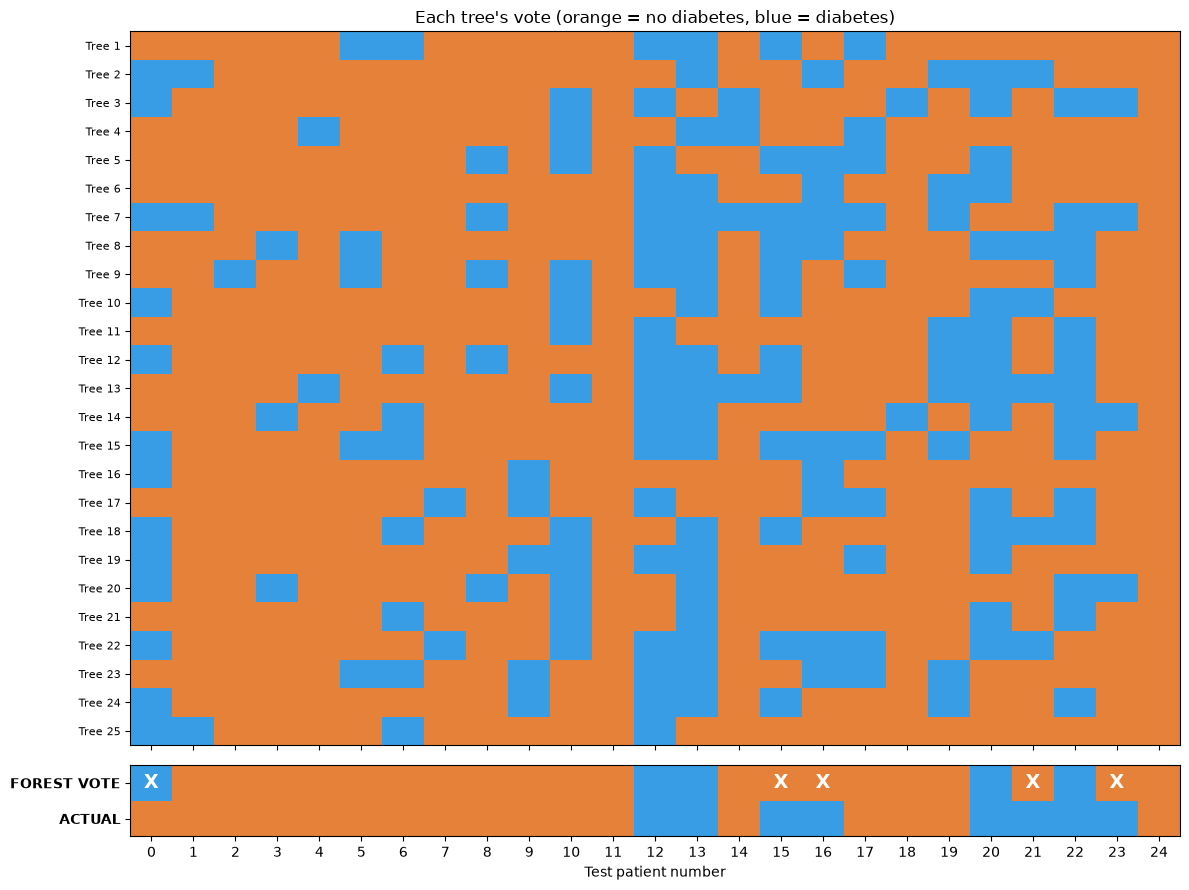

In [78]:
from matplotlib.colors import ListedColormap
two_colors = ListedColormap([NO_COLOR, YES_COLOR])
n_show = 25

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9),
                               gridspec_kw={'height_ratios': [n_trees, 2.5]}, sharex=True)
ax1.imshow(all_votes[:, :n_show], cmap=two_colors, aspect='auto', vmin=0, vmax=1)
ax1.set_yticks(range(n_trees))
ax1.set_yticklabels([f'Tree {i+1}' for i in range(n_trees)], fontsize=8)
ax1.set_title('Each tree\'s vote (orange = no diabetes, blue = diabetes)')

bottom = np.vstack([my_forest_pred[:n_show], y_test.values[:n_show]])
ax2.imshow(bottom, cmap=two_colors, aspect='auto', vmin=0, vmax=1)
ax2.set_yticks([0, 1])
ax2.set_yticklabels(['FOREST VOTE', 'ACTUAL'], fontweight='bold')
ax2.set_xticks(range(n_show))
ax2.set_xlabel('Test patient number')
for p in range(n_show):   # mark the forest's mistakes
    if bottom[0, p] != bottom[1, p]:
        ax2.text(p, 0, 'X', ha='center', va='center', color='white', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Does the crowd beat the individuals?

This is the key test. Below, each dot is the test accuracy of **one** of our 25 trees on its own. The green line is the accuracy of the **forest's vote**.

Average accuracy of a single tree:   0.696
Best single tree:                    0.766
Our hand-built forest (25 trees):    0.812


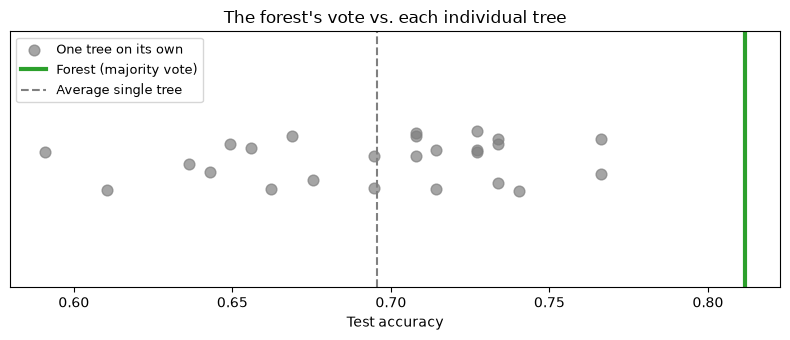

In [79]:
single_tree_accs = [metrics.accuracy_score(y_test, votes) for votes in all_votes]
my_forest_acc = metrics.accuracy_score(y_test, my_forest_pred)

print(f"Average accuracy of a single tree:   {np.mean(single_tree_accs):.3f}")
print(f"Best single tree:                    {np.max(single_tree_accs):.3f}")
print(f"Our hand-built forest (25 trees):    {my_forest_acc:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
jitter = np.random.default_rng(0).uniform(-0.15, 0.15, n_trees)
ax.scatter(single_tree_accs, jitter, s=60, alpha=0.7, color='tab:gray', label='One tree on its own')
ax.axvline(my_forest_acc, color='tab:green', linewidth=3, label='Forest (majority vote)')
ax.axvline(np.mean(single_tree_accs), color='gray', linestyle='--', label='Average single tree')
ax.set_yticks([])
ax.set_ylim(-0.6, 0.6)
ax.set_xlabel('Test accuracy')
ax.set_title('The forest\'s vote vs. each individual tree')
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

You should see the forest's accuracy sitting at or near the top of the individual trees, and clearly above the average tree, even though the forest is made of nothing but those same trees. **That is the wisdom of crowds in action.**

### Recap: the random forest recipe

1. **Bootstrap:** give each tree its own random sample of the rows (drawn with replacement).
2. **Random features:** at every question, let the tree choose from only a few random features.
3. **Grow:** grow each tree fully.
4. **Vote:** predict with the majority vote of all the trees.

Steps 1 and 2 make the trees **different**; Step 4 makes their individual mistakes **cancel out**.


## Part 4: Random Forest the Easy Way (scikit-learn)

Everything we just did by hand is built into scikit-learn's `RandomForestClassifier`. The most important settings are:

| Setting | Meaning | Matching step |
|---|---|---|
| `n_estimators=100` | how many trees to grow | Step 3 |
| `bootstrap=True` (the default) | give each tree a bootstrap sample | Step 1 |
| `max_features='sqrt'` (the default) | number of random features per question | Step 2 |
| `random_state=0` | makes the randomness repeatable | |

In [80]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=0)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

print(f"Random forest accuracy: {metrics.accuracy_score(y_test, rf_pred):.3f}")
print(f"Random forest AUC:      {metrics.roc_auc_score(y_test, rf_prob):.3f}")

Random forest accuracy: 0.792
Random forest AUC:      0.854


### A closer look at the vote for one patient

The forest's "probability of diabetes" for a patient is essentially **the fraction of trees that voted "diabetes."** (Technically, scikit-learn averages each tree's probability, a "soft vote." Fully grown trees almost always give a probability of exactly 0 or 1, so this is practically the same as counting votes.)

The individual trees live inside `rf.estimators_`. Let's check the first test patient:

In [81]:
patient = X_test.iloc[[0]]
print("Patient's measurements:")
print(patient.to_string(), "\n")

# each tree's vote for this patient (.values because the inner trees were trained without column names)
tree_votes = np.array([t.predict(patient.values)[0] for t in rf.estimators_])
print(f"Trees voting 'diabetes': {int(tree_votes.sum())} out of {len(tree_votes)}")
print(f"Forest's probability of diabetes: {rf.predict_proba(patient)[0, 1]:.2f}")
print(f"Forest's prediction: {'Diabetes' if rf.predict(patient)[0] == 1 else 'No diabetes'}")
print(f"Actual outcome:      {'Diabetes' if y_test.iloc[0] == 1 else 'No diabetes'}")

Patient's measurements:
     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  DiabetesPedigreeFunction  Age
285            7      136             74             26      135  26.0                     0.647   51 

Trees voting 'diabetes': 58 out of 100
Forest's probability of diabetes: 0.58
Forest's prediction: Diabetes
Actual outcome:      No diabetes


Because the forest's risk score comes from many trees, it can take on **many different values** (0.00, 0.01, 0.02, ..., 1.00) instead of just 3 like our small tree. This lets the forest rank patients much more finely, which is why its AUC is usually much higher.

### How many trees do we need?

More trees means a more reliable vote, but there are diminishing returns. Let's see how test accuracy changes as we add trees.

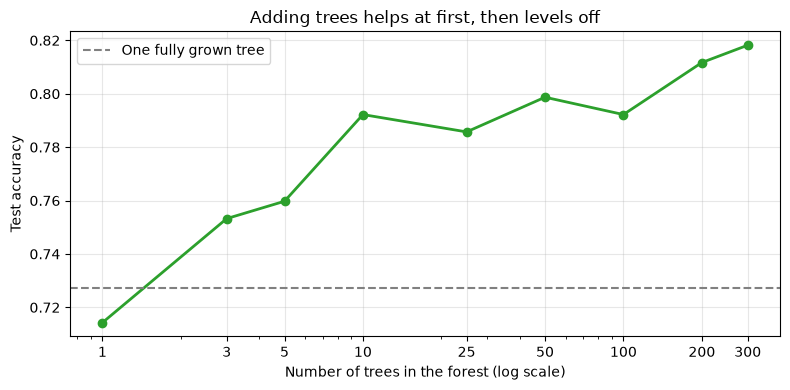

In [82]:
tree_counts = [1, 3, 5, 10, 25, 50, 100, 200, 300]
accs = []
for k in tree_counts:
    forest_k = RandomForestClassifier(n_estimators=k, random_state=0).fit(X_train, y_train)
    accs.append(forest_k.score(X_test, y_test))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tree_counts, accs, 'o-', color='tab:green', linewidth=2)
ax.axhline(full_tree.score(X_test, y_test), color='gray', linestyle='--', label='One fully grown tree')
ax.set_xscale('log')
ax.set_xticks(tree_counts)
ax.set_xticklabels(tree_counts)
ax.set_xlabel('Number of trees in the forest (log scale)')
ax.set_ylabel('Test accuracy')
ax.set_title('Adding trees helps at first, then levels off')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Accuracy improves quickly over the first few dozen trees and then levels off. (The line is a bit bumpy because our test set has only 154 patients: one patient changing from right to wrong moves accuracy by about 0.6%.) Adding more trees almost never *hurts* accuracy; it just makes the model slower to train.

### Bonus: a free test set from the "left-out" patients (out-of-bag score)

Remember from Step 1 that each tree never sees about 37% of the training patients. Those patients are called **out-of-bag** (OOB) for that tree. We can test each training patient using only the trees that did *not* see it. This gives an honest accuracy estimate without touching the test set at all.

In [83]:
rf_oob = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=0).fit(X_train, y_train)
print(f"Out-of-bag accuracy estimate (training data only): {rf_oob.oob_score_:.3f}")
print(f"Accuracy on the real test set:                     {rf_oob.score(X_test, y_test):.3f}")

Out-of-bag accuracy estimate (training data only): 0.748
Accuracy on the real test set:                     0.792


### Which features matter most? (feature importance)

Every time a tree asks a question, the Gini impurity goes down. A feature's **importance** adds up how much that feature reduced impurity across all questions in all 100 trees. The scores are scaled to add up to 1.

A word of caution: importance tells us which features the model *found useful for predicting*. It does **not** prove that a feature *causes* diabetes.

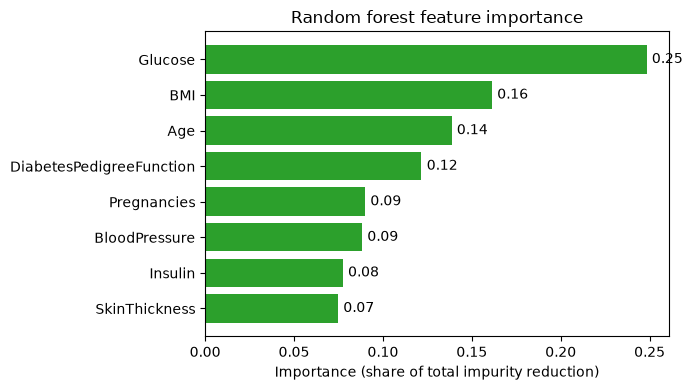

In [84]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importances.index, importances.values, color='tab:green')
for i, v in enumerate(importances.values):
    ax.text(v + 0.003, i, f'{v:.2f}', va='center')
ax.set_xlabel('Importance (share of total impurity reduction)')
ax.set_title('Random forest feature importance')
plt.tight_layout()
plt.show()

Compare this chart with the histograms from Part 0. Do the features the forest relies on most match the ones where the orange and blue histograms were most separated?



## Part 5: Comparing the Models

### Scorecard

In [85]:
results = pd.DataFrame({
    'Model': ['Small tree (3 leaves)', 'Fully grown tree', 'Hand-built forest (25 trees)', 'scikit-learn forest (100 trees)'],
    'Accuracy': [tree_acc,
                 full_tree.score(X_test, y_test),
                 my_forest_acc,
                 metrics.accuracy_score(y_test, rf_pred)],
    'AUC': [metrics.roc_auc_score(y_test, y_pred_prob),
            metrics.roc_auc_score(y_test, full_tree.predict_proba(X_test)[:, 1]),
            metrics.roc_auc_score(y_test, all_votes.mean(axis=0)),   # fraction of 'yes' votes as the risk score
            metrics.roc_auc_score(y_test, rf_prob)],
})
results.round(3)

,Model,Accuracy,AUC
0,Small tree (3 leaves),0.799,0.752
1,Fully grown tree,0.727,0.691
2,Hand-built forest (25 trees),0.812,0.862
3,scikit-learn forest (100 trees),0.792,0.854


**How to read this table:**

* The fairest comparison is **fully grown tree vs. forest**, since a forest is made of fully grown trees. Voting should give the forest a clear advantage over one big tree.
* The tiny 3-leaf tree may have an accuracy that is close to (or even above) the forest on this particular test set. Small, simple models can be surprisingly competitive! But look at the **AUC** column: the forest is usually much better at **ranking** patients by risk.
* With only 154 test patients, a single accuracy number is a bit noisy. The next experiment deals with that.

### Side-by-side confusion matrices

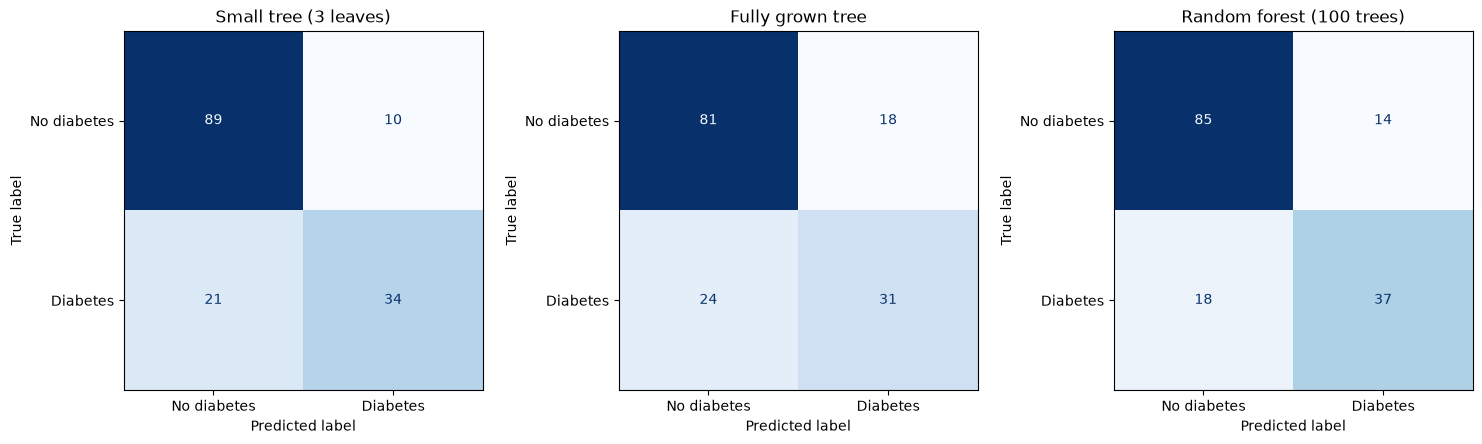

In [86]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, preds) in zip(axes, [('Small tree (3 leaves)', y_pred_class),
                                    ('Fully grown tree', full_tree.predict(X_test)),
                                    ('Random forest (100 trees)', rf_pred)]):
    ConfusionMatrixDisplay.from_predictions(y_test, preds, display_labels=['No diabetes', 'Diabetes'],
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### ROC curves

An **ROC curve** shows the trade-off a model faces when we move the cut-off for saying "diabetes":

* The vertical axis is the share of diabetic patients we correctly catch (**true positive rate**).
* The horizontal axis is the share of healthy patients we wrongly flag (**false positive rate**).

A curve that hugs the **top-left corner** is better. The diagonal dashed line is a coin flip. The AUC is the area under each curve.

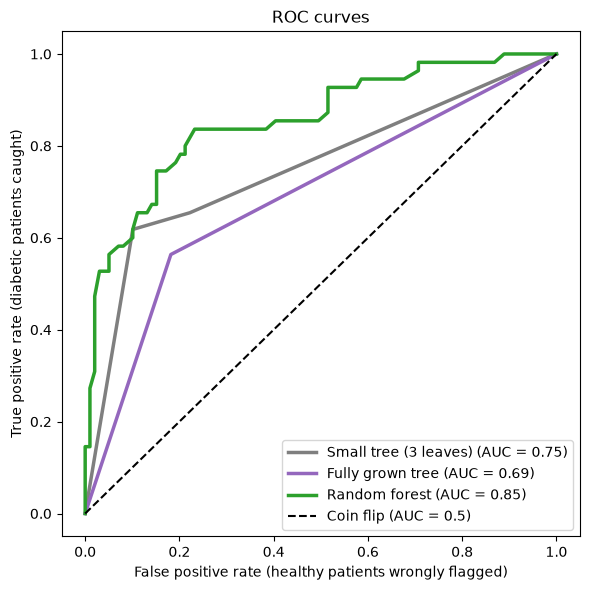

In [87]:
fig, ax = plt.subplots(figsize=(6, 6))
roc_models = [('Small tree (3 leaves)', y_pred_prob, 'tab:gray'),
              ('Fully grown tree', full_tree.predict_proba(X_test)[:, 1], 'tab:purple'),
              ('Random forest', rf_prob, 'tab:green')]
for name, probs, color in roc_models:
    fpr, tpr, _ = metrics.roc_curve(y_test, probs)
    auc = metrics.roc_auc_score(y_test, probs)
    ax.plot(fpr, tpr, color=color, linewidth=2.5, label=f'{name} (AUC = {auc:.2f})')
ax.plot([0, 1], [0, 1], 'k--', label='Coin flip (AUC = 0.5)')
ax.set_xlabel('False positive rate (healthy patients wrongly flagged)')
ax.set_ylabel('True positive rate (diabetic patients caught)')
ax.set_title('ROC curves')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

Notice that the small tree's "curve" is just a few straight segments: with only 3 possible risk scores, it has only a few cut-offs to choose from. The fully grown tree is even coarser: its leaves are pure, so it only ever says 0% or 100%, and its "curve" has a single bend. The forest's risk scores come from 100 votes, so its curve is much smoother.

### Was our test split lucky? Repeat the experiment many times

All our results so far come from **one** random split into training and testing patients. A different split might tell a different story. Let's redo the whole experiment with **30 different random splits** and look at the spread of results for each model.

(This may take 20 to 30 seconds to run.)

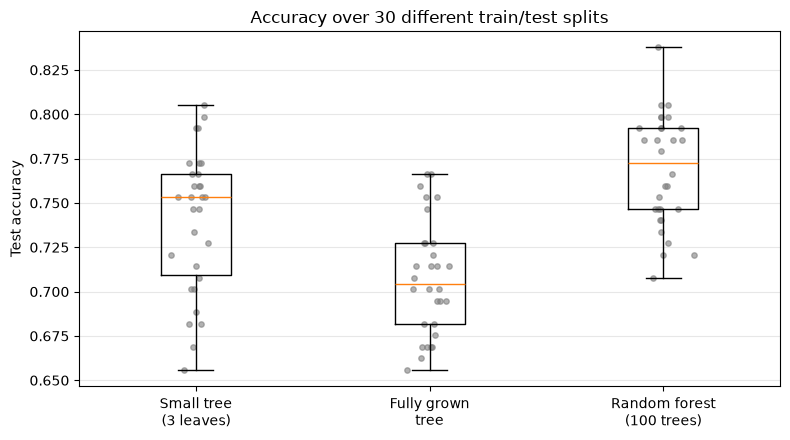

Small tree (3 leaves)        average accuracy = 0.740
Fully grown tree             average accuracy = 0.708
Random forest (100 trees)    average accuracy = 0.768


In [88]:
model_makers = {
    'Small tree\n(3 leaves)': lambda: DecisionTreeClassifier(max_leaf_nodes=3, random_state=0),
    'Fully grown\ntree':      lambda: DecisionTreeClassifier(random_state=0),
    'Random forest\n(100 trees)': lambda: RandomForestClassifier(n_estimators=100, random_state=0),
}
repeat_results = {name: [] for name in model_makers}

for seed in range(30):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, random_state=seed)
    for name, make in model_makers.items():
        repeat_results[name].append(make().fit(Xtr, ytr).score(Xte, yte))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(list(repeat_results.values()))
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(list(repeat_results.keys()))
for i, scores in enumerate(repeat_results.values(), start=1):
    ax.scatter(np.random.default_rng(i).normal(i, 0.04, len(scores)), scores, color='tab:gray', alpha=0.6, s=15)
ax.set_ylabel('Test accuracy')
ax.set_title('Accuracy over 30 different train/test splits')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

for name, scores in repeat_results.items():
    print(f"{name.replace(chr(10), ' '):<28} average accuracy = {np.mean(scores):.3f}")

Each box shows the middle half of the 30 results, and the line inside the box is the middle (median) result. Looking across many splits gives a much more trustworthy picture than any single split. Ask yourself: which model has the highest typical accuracy, and how does the fully grown tree compare to the forest that is built from trees just like it?

### Seeing the difference: decision boundaries

With 8 features we cannot draw what a model is "thinking." But if we train models on just **two** features, `Glucose` and `BMI`, we can color every point on a 2D map by the model's predicted chance of diabetes. The dots are test patients (circles = no diabetes, triangles = diabetes). Orange areas mean the model predicts "no diabetes", blue areas mean "diabetes", and white means the model is unsure (about 50/50).

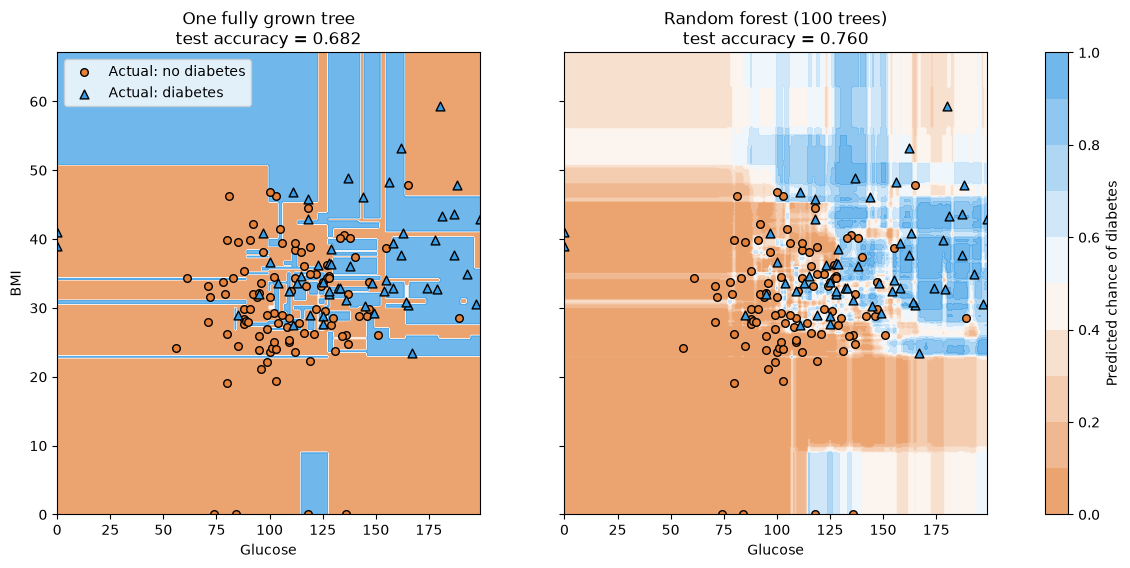

In [89]:
two_feats = ['Glucose', 'BMI']
tree_2d = DecisionTreeClassifier(random_state=0).fit(X_train[two_feats], y_train)
rf_2d = RandomForestClassifier(n_estimators=100, random_state=0).fit(X_train[two_feats], y_train)

# a grid of (Glucose, BMI) points covering the whole map
g_vals = np.linspace(X[two_feats[0]].min(), X[two_feats[0]].max(), 250)
b_vals = np.linspace(X[two_feats[1]].min(), X[two_feats[1]].max(), 250)
G, B = np.meshgrid(g_vals, b_vals)
grid = pd.DataFrame({two_feats[0]: G.ravel(), two_feats[1]: B.ravel()})

from matplotlib.colors import LinearSegmentedColormap
prob_cmap = LinearSegmentedColormap.from_list('prob', [NO_COLOR, 'white', YES_COLOR])

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, (name, m) in zip(axes, [('One fully grown tree', tree_2d), ('Random forest (100 trees)', rf_2d)]):
    prob = m.predict_proba(grid)[:, 1].reshape(G.shape)
    cs = ax.contourf(G, B, prob, levels=np.linspace(0, 1, 11), cmap=prob_cmap, alpha=0.8)
    ax.scatter(X_test.loc[y_test == 0, two_feats[0]], X_test.loc[y_test == 0, two_feats[1]],
               c=NO_COLOR, marker='o', edgecolor='k', s=30, label='Actual: no diabetes')
    ax.scatter(X_test.loc[y_test == 1, two_feats[0]], X_test.loc[y_test == 1, two_feats[1]],
               c=YES_COLOR, marker='^', edgecolor='k', s=40, label='Actual: diabetes')
    acc = m.score(X_test[two_feats], y_test)
    ax.set_title(f'{name}\ntest accuracy = {acc:.3f}')
    ax.set_xlabel(two_feats[0])
axes[0].set_ylabel(two_feats[1])
axes[0].legend(loc='upper left')
fig.colorbar(cs, ax=axes, label='Predicted chance of diabetes')
plt.show()

**What to notice:**

* A decision tree can only draw **straight lines parallel to the axes** (because every question is "Is feature ≤ some number?"), so its map is made of rectangles.
* The single fully grown tree's map is **all-or-nothing** (only solid orange and solid blue) and full of tiny islands. Those islands are the tree memorizing individual training patients: overfitting you can see.
* The forest averages 100 different maps. The result has **softer, more gradual** regions that show uncertainty in the overlapping middle area, and fewer isolated islands.


## Summary

**Decision tree**

* A flowchart of yes/no questions learned from data.
* Chooses each question to make the groups as pure as possible (lowest Gini impurity).
* Easy to draw and explain, but big trees **overfit** and small changes in the data can produce a very different tree (**unstable**).

**Random forest**

* Many decision trees that **vote**.
* Two sources of randomness make the trees different from each other:
  1. each tree trains on a **bootstrap sample** of the rows, and
  2. each question considers only a **random few features**.
* Individual trees make different mistakes, and the vote cancels many of them out.
* Usually more accurate and much more stable than one tree, gives finer-grained risk scores, and reports feature importance.
* The trade-off: a forest of 100 trees is much harder to draw or explain than one small tree.

| | Single decision tree | Random forest |
|---|---|---|
| Easy to explain? | Yes, you can draw it | Not really, 100 trees |
| Overfitting | High risk when deep | Much lower |
| Stability | Changes a lot with the data | Stable |
| Risk scores | Coarse (few values) | Fine-grained |
| Speed | Very fast | Slower (but still fast here) |

**Vocabulary:** feature, target, training set, testing set, root, branch, leaf, Gini impurity, overfitting, variance/instability, bootstrap sample, out-of-bag, majority vote, ensemble, accuracy, confusion matrix, false negative, ROC curve, AUC, feature importance.


